# Baseline XGBoost — EDA sampai submission.csv

    Notebook ini mereview pipeline yang menghasilkan **artifacts/optimization/submission_baseline_0_52623.csv**.
    Skor public historis: **0.52623**.
    Skor tersebut milik file historis, bukan jaminan untuk eksperimen yang Anda ubah.

    **Urutan membaca:** persiapan → EDA → pembentukan fitur → preprocessing →
    validasi dan pemilihan model → prediksi test → pemeriksaan dan ekspor CSV.

    Jalankan **Kernel → Restart & Run All**. Model/fitur cache dipakai jika tersedia;
    `.fit()` otomatis berjalan jika model belum tersedia. Untuk melatih ulang seluruhnya,
    ubah flag pada sel persiapan. Pencarian parameter yang mahal bersifat opsional.

    Output setiap notebook disimpan pada direktori versinya sendiri dengan nama
    **submission.csv**, agar hasil beberapa versi bisa dibandingkan.
    Notebook tidak mengirim submission ke Kaggle.

    Instal dependensi dari direktori proyek: `python -m pip install -r requirements-optimization.txt -r requirements-notebook.txt`.
    Data mentah harus tersedia di `data/raw/`; unduh sekali dengan `python scripts/download_data.py`.
    Kredensial tidak perlu ditulis dalam notebook.

## 1. Persiapan lingkungan

Semua jalur relatif terhadap proyek. Cache mempercepat review; kode training tetap ada di sel notebook.

In [1]:
RUN_NAME = "01_baseline"
CANONICAL_FILE = "artifacts/optimization/submission_baseline_0_52623.csv"
PUBLIC_SCORE = 0.52623

from pathlib import Path
import gc, hashlib, itertools, json, os, time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.stats import ks_2samp
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer, MissingIndicator
from sklearn.metrics import average_precision_score, log_loss, roc_auc_score, roc_curve
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, SplineTransformer, StandardScaler
from sklearn.linear_model import LogisticRegression
from threadpoolctl import threadpool_limits
from xgboost import XGBClassifier
from xgboost.callback import EarlyStopping
from lightgbm import LGBMClassifier, early_stopping, log_evaluation
from catboost import CatBoostClassifier

# Ubah empat pilihan ini jika ingin membangun dan melatih semuanya ulang.
FORCE_REBUILD_FEATURES = False
FORCE_RETRAIN_MODELS = False
FORCE_RECOMPUTE_VALIDATION = False
RUN_OPTIONAL_SEARCH = False

ROOT = Path(os.environ.get("LOGIKA_PROJECT_DIR", Path.cwd())).resolve()
if not (ROOT / "scripts/analyze.py").exists():
    ROOT = next(p for p in ROOT.parents if (p / "scripts/analyze.py").exists())
RAW = ROOT / "data/raw"
PROCESSED = Path(os.environ.get("LOGIKA_FEATURE_DIR", ROOT / "data/processed"))
OUT = ROOT / "artifacts/notebook_runs" / RUN_NAME
TABLES = OUT / "tables"
for folder in [PROCESSED, OUT, TABLES, OUT / "models"]:
    folder.mkdir(parents=True, exist_ok=True)
KEY, TARGET = "customer_id", "target"
EXCLUDED = {
    "application_id",
    "customer_id",
    "application_datetime",
    "decision_datetime",
    "target",
    "split",
}
pd.set_option("display.max_columns", 12)
pd.set_option("display.max_rows", 20)
print("Proyek:", ROOT)
print("Output notebook:", OUT / "submission.csv")

Proyek: /home/taqiyudinmiftah/Logika
Output notebook: /home/taqiyudinmiftah/Logika/artifacts/notebook_runs/01_baseline/submission.csv


## 2. Memahami target dan data

`target=1` berarti pinjaman mencapai DPD ≥90 dalam 12 bulan setelah origination. Test tidak memiliki target. Ada satu aplikasi terpilih per customer, sehingga agregasi seluruh tabel riwayat memakai customer_id. Perbedaan rasio target menurut kelompok bersifat deskriptif dan bukan kesimpulan sebab-akibat.

,dataset,baris,kolom,target_positif,rasio_positif
0,train,70000,10,9507.0,0.135814
1,test,30000,9,NaN,NaN


,tipe,missing
application_id,object,0
customer_id,object,0
application_datetime,datetime64[ns],0
decision_datetime,datetime64[ns],0
loan_amount,int64,0
term_months,int64,0
annual_interest_rate,float64,0
proposed_monthly_installment,int64,0
loan_purpose,object,0
target,int64,0


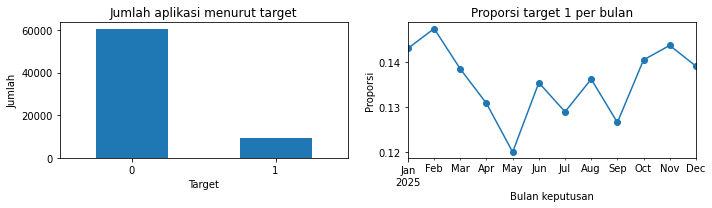

,aplikasi,rasio_target_1
employment_type,,
salaried,33473,0.132405
self_employed,20987,0.137943
variable_income,15540,0.140283


Urutan sample sama dengan test: False


In [2]:
train_raw = pd.read_csv(
    RAW / "train_applications.csv", parse_dates=["application_datetime", "decision_datetime"]
)
test_raw = pd.read_csv(
    RAW / "test_applications.csv", parse_dates=["application_datetime", "decision_datetime"]
)
sample = pd.read_csv(RAW / "sample_submission.csv")
profiles_eda = pd.read_csv(RAW / "customer_profiles.csv")
assert train_raw.application_id.is_unique and test_raw.application_id.is_unique
assert set(train_raw.customer_id).isdisjoint(test_raw.customer_id)
assert set(test_raw.application_id) == set(sample.application_id)
assert train_raw.target.isin([0, 1]).all()
display(
    pd.DataFrame(
        [
            {
                "dataset": "train",
                "baris": len(train_raw),
                "kolom": len(train_raw.columns),
                "target_positif": int(train_raw.target.sum()),
                "rasio_positif": train_raw.target.mean(),
            },
            {
                "dataset": "test",
                "baris": len(test_raw),
                "kolom": len(test_raw.columns),
                "target_positif": np.nan,
                "rasio_positif": np.nan,
            },
        ]
    )
)
display(
    pd.DataFrame({"tipe": train_raw.dtypes.astype(str), "missing": train_raw.isna().sum()})
)
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
train_raw.target.value_counts().sort_index().plot.bar(ax=axes[0], rot=0)
axes[0].set(title="Jumlah aplikasi menurut target", xlabel="Target", ylabel="Jumlah")
monthly = train_raw.groupby(train_raw.decision_datetime.dt.to_period("M")).target.agg(
    ["mean", "size"]
)
monthly["mean"].plot(marker="o", ax=axes[1])
axes[1].set(title="Proporsi target 1 per bulan", xlabel="Bulan keputusan", ylabel="Proporsi")
plt.tight_layout()
plt.show()
profile = train_raw[["customer_id", "target"]].merge(
    profiles_eda, on="customer_id", validate="one_to_one"
)
display(profile.groupby("employment_type").target.agg(aplikasi="size", rasio_target_1="mean"))
print("Urutan sample sama dengan test:", sample.application_id.equals(test_raw.application_id))
del profile, profiles_eda

## 3. Metrik KS dan risiko kebocoran

KS adalah maksimum selisih dua distribusi kumulatif skor. Dalam ROC, nilainya sama dengan maksimum |TPR−FPR|. KS mengukur pemisahan; submission tetap berupa probabilitas kontinu. Model validasi tidak boleh dilatih pada baris validasi. Informasi riwayat harus tersedia sebelum decision_datetime, dan opaque ID tidak menjadi fitur.

In [3]:
def ks(y, probability):
    fpr, tpr, _ = roc_curve(y, probability, drop_intermediate=False)
    return float(np.max(np.abs(tpr - fpr)))


def lgb_ks(y, probability):
    return "ks", ks(y, probability), True


def metrics(y, probability):
    return {
        "ks": ks(y, probability),
        "roc_auc": roc_auc_score(y, probability),
        "average_precision": average_precision_score(y, probability),
        "log_loss": log_loss(y, probability),
    }

## 4. Fitur dasar: alat bantu dan pengaturan cache

Sel fitur berikut berisi kode agregasi yang digunakan pada eksperimen asli. Jika parquet tersedia, blok `if NEED_...` dilewati. Aktifkan `FORCE_REBUILD_FEATURES` untuk membaca ulang seluruh riwayat. Kode tetap terlihat dan dapat diedit langsung di notebook.

In [4]:
def safe_ratio(a, b):
    return a / b.where(b > 0)


def read(name, dates=()):
    return pd.read_csv(RAW / f"{name}.csv", parse_dates=list(dates))


def ratio(a, b):
    return a / b.where(b > 0)


NEED_BASE = FORCE_REBUILD_FEATURES or not (PROCESSED / "application_features.parquet").exists()
print("Bangun fitur dasar:", NEED_BASE)

Bangun fitur dasar: False


### Persiapan audit

Setiap aplikasi memiliki satu customer. Audit mencatat duplikasi, relasi tabel, missing value, dan ketersediaan riwayat.

In [5]:
if NEED_BASE:
    for folder in [PROCESSED, TABLES, OUT / "figures"]:
        folder.mkdir(parents=True, exist_ok=True)
    train = read("train_applications", ["application_datetime", "decision_datetime"])
    test = read("test_applications", ["application_datetime", "decision_datetime"])
    train["split"] = "train"
    test["split"] = "test"
    base = pd.concat([train, test], ignore_index=True)
    assert base.application_id.is_unique and base.customer_id.is_unique
    cutoff = base[[KEY, "decision_datetime"]].rename(columns={"decision_datetime": "cutoff"})
    inventory, missing, audits, coverage = [], [], {}, []

    def inspect(df, name, primary):
        inventory.append(
            {
                "table": name,
                "rows": len(df),
                "columns": len(df.columns),
                "customers": df[KEY].nunique() if KEY in df else np.nan,
                "size_mb": (RAW / f"{name}.csv").stat().st_size / 1e6,
            }
        )
        for col in df:
            missing.append(
                {
                    "table": name,
                    "column": col,
                    "dtype": str(df[col].dtype),
                    "missing": int(df[col].isna().sum()),
                    "missing_pct": 100 * df[col].isna().mean(),
                    "unique_values": df[col].nunique(),
                }
            )
        audits[name] = {
            "duplicate_rows": int(df.duplicated().sum()),
            "duplicate_primary_keys": int(df.duplicated(primary).sum()),
        }
        if KEY in df:
            ids = set(df[KEY])
            audits[name]["orphan_customers"] = len(ids - set(base[KEY]))
            for part in ["train", "test"]:
                subset = base[base.split.eq(part)]
                coverage.append(
                    {
                        "table": name,
                        "split": part,
                        "covered_customers": int(subset[KEY].isin(ids).sum()),
                        "coverage_pct": 100 * subset[KEY].isin(ids).mean(),
                    }
                )
        print(f"Audited {name}: {len(df):,} rows", flush=True)

    def at_cutoff(df, name, cols):
        df = df.merge(cutoff, on=KEY, how="left", validate="many_to_one")
        assert df.cutoff.notna().all()
        for col in cols:
            audits[name][f"{col}_at_or_after_cutoff"] = int(df[col].ge(df.cutoff).sum())
        return df

    def attach(features):
        global base
        assert features.index.is_unique
        base = base.merge(
            features, left_on=KEY, right_index=True, how="left", validate="one_to_one"
        )
        assert len(base) == len(train) + len(test)

### Profil dan rasio kemampuan bayar

Gabungkan profil satu-ke-satu; rasio cicilan/pendapatan lebih mudah dipelajari model daripada dua jumlah rupiah terpisah.

In [6]:
if NEED_BASE:
    inspect(train.drop(columns="split"), "train_applications", "application_id")
    inspect(test.drop(columns="split"), "test_applications", "application_id")
    submission = read("sample_submission")
    inspect(submission, "sample_submission", "application_id")
    audits["submission"] = {
        "same_id_set_as_test": set(submission.application_id) == set(test.application_id),
        "same_row_order_as_test": submission.application_id.equals(test.application_id),
        "target_column": "default_probability",
    }
    profiles = read("customer_profiles")
    inspect(profiles, "customer_profiles", KEY)
    base = base.merge(profiles, on=KEY, how="left", validate="one_to_one")
    assert base.age.notna().all()
    base["installment_income_ratio"] = safe_ratio(
        base.proposed_monthly_installment, base.declared_monthly_income
    )
    base["loan_income_ratio"] = safe_ratio(base.loan_amount, base.declared_monthly_income)
    base["income_per_dependent"] = base.declared_monthly_income / (1 + base.dependents)
    base["decision_delay_hours"] = (
        base.decision_datetime - base.application_datetime
    ).dt.total_seconds() / 3600
    rate = base.annual_interest_rate / 12
    theoretical = (
        base.loan_amount
        * rate
        * (1 + rate) ** base.term_months
        / ((1 + rate) ** base.term_months - 1)
    )
    audits["applications"] = {
        "train_test_customer_overlap": len(set(train[KEY]) & set(test[KEY])),
        "train_test_application_overlap": len(
            set(train.application_id) & set(test.application_id)
        ),
        "decision_before_application": int(
            (base.decision_datetime < base.application_datetime).sum()
        ),
        "nonpositive_income": int(base.declared_monthly_income.le(0).sum()),
        "installment_formula_max_rounding_difference_idr": float(
            abs(base.proposed_monthly_installment - theoretical.round()).max()
        ),
        "term_months_values": sorted(base.term_months.unique().tolist()),
    }
    del profiles

### Riwayat aplikasi

Ambil keputusan sebelum cutoff. Hitung persetujuan, penolakan, dan jarak waktu aplikasi terakhir.

In [7]:
if NEED_BASE:
    name = "previous_applications"
    prev = read(name, ["application_datetime", "decision_datetime"])
    inspect(prev, name, "application_id")
    historical_ids = set(prev.application_id)
    approved_loans = set(prev.loan_id.dropna())
    loan_customers = prev.loc[prev.loan_id.notna(), ["loan_id", KEY]].set_index("loan_id")[KEY]
    audits[name]["overlap_with_selected_application_ids"] = len(
        historical_ids & set(base.application_id)
    )
    prev = at_cutoff(prev, name, ["application_datetime", "decision_datetime"])
    prev = prev[prev.decision_datetime.lt(prev.cutoff)].copy()
    for status in ["approved", "rejected", "cancelled"]:
        prev[f"is_{status}"] = prev.decision.eq(status).astype(int)
    prev["recency_days"] = (prev.cutoff - prev.decision_datetime).dt.total_seconds() / 86400
    features = prev.groupby(KEY).agg(
        previous_count=("application_id", "size"),
        previous_approved_count=("is_approved", "sum"),
        previous_rejection_rate=("is_rejected", "mean"),
        previous_cancel_rate=("is_cancelled", "mean"),
        previous_requested_mean=("requested_amount", "mean"),
        previous_approved_amount_mean=("approved_amount", "mean"),
        previous_installment_mean=("scheduled_monthly_installment", "mean"),
        previous_last_recency_days=("recency_days", "min"),
    )
    for days in [90, 180]:
        features[f"previous_count_{days}d"] = (
            prev[prev.recency_days.le(days)]
            .groupby(KEY)
            .size()
            .reindex(features.index, fill_value=0)
        )
    attach(features)
    base["has_previous"] = base.previous_count.notna().astype(int)
    del prev, features
    gc.collect()

### Riwayat pembayaran

DPD adalah days past due. Snapshot pembayaran harus diketahui sebelum keputusan, termasuk waktu pembayaran terakhir.

In [8]:
if NEED_BASE:
    name = "repayment_history"
    repay = read(name, ["due_date", "last_payment_datetime"])
    inspect(repay, name, "installment_id")
    audits[name]["loans_not_in_approved_history"] = len(set(repay.loan_id) - approved_loans)
    audits[name]["loan_customer_mismatches"] = int(
        repay.loan_id.map(loan_customers).ne(repay[KEY]).sum()
    )
    audits[name]["amount_paid_above_due"] = int(repay.amount_paid.gt(repay.amount_due).sum())
    audits[name]["max_dpd_below_current_dpd"] = int(
        repay.max_days_past_due.lt(repay.days_past_due).sum()
    )
    repay = at_cutoff(repay, name, ["due_date", "last_payment_datetime"])
    repay = repay[repay.due_date.lt(repay.cutoff)].copy()
    # Snapshot amounts/DPD are already measured before the selected decision.
    # Any future observed payment would invalidate this snapshot; do not silently use it.
    assert (
        repay.last_payment_datetime.dropna()
        .lt(repay.loc[repay.last_payment_datetime.notna(), "cutoff"])
        .all()
    )
    repay["unpaid_amount"] = (repay.amount_due - repay.amount_paid).clip(lower=0)
    for threshold in [1, 30, 90]:
        repay[f"ever_dpd_{threshold}"] = repay.max_days_past_due.ge(threshold).astype(int)
    repay["recency_days"] = (repay.cutoff - repay.due_date).dt.total_seconds() / 86400
    features = repay.groupby(KEY).agg(
        repayment_installment_count=("installment_id", "size"),
        repayment_loan_count=("loan_id", "nunique"),
        repayment_amount_due=("amount_due", "sum"),
        repayment_amount_paid=("amount_paid", "sum"),
        repayment_unpaid_amount=("unpaid_amount", "sum"),
        repayment_current_dpd_max=("days_past_due", "max"),
        repayment_historical_dpd_max=("max_days_past_due", "max"),
        repayment_historical_dpd_mean=("max_days_past_due", "mean"),
        repayment_late_share=("ever_dpd_1", "mean"),
        repayment_dpd30_share=("ever_dpd_30", "mean"),
        repayment_dpd90_share=("ever_dpd_90", "mean"),
    )
    features["repayment_paid_ratio"] = safe_ratio(
        features.repayment_amount_paid, features.repayment_amount_due
    )
    recent = (
        repay[repay.recency_days.le(180)]
        .groupby(KEY)
        .agg(
            repayment_dpd_mean_180d=("max_days_past_due", "mean"),
            repayment_unpaid_180d=("unpaid_amount", "sum"),
        )
    )
    attach(features.join(recent))
    base["has_repayments"] = base.repayment_installment_count.notna().astype(int)
    del repay, features, recent
    gc.collect()

### Perilaku rekening

Hanya bulan kalender yang sudah selesai yang digunakan; rangkum pemasukan, pengeluaran, saldo, dan hari saldo rendah.

In [9]:
if NEED_BASE:
    name = "account_behavior"
    account = read(name, ["month"])
    inspect(account, name, [KEY, "month"])
    account = at_cutoff(account, name, ["month"])
    completed = account.month + pd.offsets.MonthBegin(1)
    audits[name]["incomplete_month_at_cutoff"] = int(completed.gt(account.cutoff).sum())
    audits[name]["balance_identity_mismatches"] = int(
        (account.opening_balance + account.inflows - account.outflows)
        .ne(account.closing_balance)
        .sum()
    )
    audits[name]["negative_amount_cells"] = int(
        account.select_dtypes(include="number").lt(0).sum().sum()
    )
    account = account[completed.le(account.cutoff)].copy()
    account["net_inflow"] = account.inflows - account.outflows
    account["recency_days"] = (account.cutoff - account.month).dt.total_seconds() / 86400
    features = account.groupby(KEY).agg(
        account_month_count=("month", "size"),
        account_income_mean=("income_like_credits", "mean"),
        account_income_std=("income_like_credits", "std"),
        account_inflow_mean=("inflows", "mean"),
        account_outflow_mean=("outflows", "mean"),
        account_net_inflow_mean=("net_inflow", "mean"),
        account_average_balance_mean=("average_balance", "mean"),
        account_minimum_balance_min=("minimum_balance", "min"),
        account_low_balance_days_mean=("low_balance_days", "mean"),
        account_last_recency_days=("recency_days", "min"),
    )
    features["account_income_cv"] = safe_ratio(
        features.account_income_std, features.account_income_mean
    )
    last = account.sort_values("month").groupby(KEY).tail(1).set_index(KEY)
    for col in [
        "closing_balance",
        "income_like_credits",
        "average_balance",
        "low_balance_days",
    ]:
        features[f"account_last_{col}"] = last[col]
    # Three complete months immediately preceding the decision month.
    start = account.cutoff.dt.to_period("M").dt.to_timestamp() - pd.DateOffset(months=3)
    recent = (
        account[account.month.ge(start)]
        .groupby(KEY)
        .agg(
            account_income_mean_3m=("income_like_credits", "mean"),
            account_outflow_mean_3m=("outflows", "mean"),
            account_balance_mean_3m=("average_balance", "mean"),
            account_low_balance_days_mean_3m=("low_balance_days", "mean"),
        )
    )
    attach(features.join(recent))
    base["has_account"] = base.account_month_count.notna().astype(int)
    base["observed_declared_income_ratio"] = safe_ratio(
        base.account_income_mean, base.declared_monthly_income
    )
    base["installment_observed_income_ratio"] = safe_ratio(
        base.proposed_monthly_installment, base.account_income_mean
    )
    base["balance_installment_ratio"] = safe_ratio(
        base.account_last_closing_balance, base.proposed_monthly_installment
    )
    del account, features, last, recent
    gc.collect()

### Biro kredit

Laporan harus sudah dibuat dan tersedia sebelum cutoff. Gunakan laporan terakhir per provider; saldo provider tidak dijumlahkan karena cakupan dapat tumpang tindih.

In [10]:
if NEED_BASE:
    name = "bureau_observations"
    bureau = read(name, ["report_datetime", "available_datetime"])
    inspect(bureau, name, "bureau_observation_id")
    audits[name]["unknown_application_ids"] = len(
        set(bureau.application_id) - (historical_ids | set(base.application_id))
    )
    audits[name]["availability_before_report"] = int(
        bureau.available_datetime.lt(bureau.report_datetime).sum()
    )
    audits[name]["score_out_of_range"] = int(
        (bureau.score.notna() & ~bureau.score.between(300, 850)).sum()
    )
    expected_util = safe_ratio(
        bureau.revolving_outstanding_balance, bureau.revolving_credit_limit
    )
    audits[name]["utilization_max_absolute_difference"] = float(
        (bureau.utilization - expected_util).abs().max()
    )
    bureau = at_cutoff(bureau, name, ["report_datetime", "available_datetime"])
    bureau = bureau[
        bureau.report_datetime.lt(bureau.cutoff) & bureau.available_datetime.lt(bureau.cutoff)
    ].copy()
    latest = (
        bureau.sort_values(["report_datetime", "available_datetime", "bureau_observation_id"])
        .groupby([KEY, "bureau_provider"])
        .tail(1)
        .copy()
    )
    latest["report_age_days"] = (
        latest.cutoff - latest.report_datetime
    ).dt.total_seconds() / 86400
    latest["delivery_lag_days"] = (
        latest.available_datetime - latest.report_datetime
    ).dt.total_seconds() / 86400
    features = latest.groupby(KEY).agg(
        bureau_provider_count=("bureau_provider", "size"),
        bureau_scored_count=("score", "count"),
        bureau_score_mean=("score", "mean"),
        bureau_score_min=("score", "min"),
        bureau_score_max=("score", "max"),
        bureau_debt_max=("outstanding_balance", "max"),
        bureau_debt_mean=("outstanding_balance", "mean"),
        bureau_active_accounts_max=("active_accounts", "max"),
        bureau_utilization_max=("utilization", "max"),
        bureau_inquiries_max=("inquiries_last_6m", "max"),
        bureau_delinquent_accounts_max=("delinquent_accounts_last_12m", "max"),
        bureau_report_age_mean=("report_age_days", "mean"),
        bureau_delivery_lag_mean=("delivery_lag_days", "mean"),
    )
    features["bureau_score_spread"] = features.bureau_score_max - features.bureau_score_min
    # Provider balances can overlap; summing would imply unsupported unique debt.
    for col in ["score", "utilization", "outstanding_balance", "report_age_days"]:
        pivot = latest.pivot(index=KEY, columns="bureau_provider", values=col)
        pivot.columns = [f"bureau_{provider}_{col}" for provider in pivot.columns]
        features = features.join(pivot)
    attach(features)
    base["bureau_debt_income_ratio"] = safe_ratio(
        base.bureau_debt_max, base.declared_monthly_income
    )
    latest.drop(columns="cutoff").to_parquet(PROCESSED / "bureau_latest.parquet", index=False)
    del bureau, latest, features, pivot
    gc.collect()

### Transaksi e-commerce

`order_total` berulang di setiap barang. Deduplicasi pesanan sebelum menjumlahkan belanja; transaksi cancelled bukan pengeluaran.

In [11]:
if NEED_BASE:
    name = "ecommerce_transactions"
    ecom = read(name, ["transaction_datetime"])
    inspect(ecom, name, "order_item_id")
    # A transaction row is an ITEM, not an order. Verify before deduplicating.
    order_fields = [
        KEY,
        "transaction_datetime",
        "order_total",
        "payment_method",
        "order_status",
    ]
    inconsistent = (
        ecom.groupby("order_id")[order_fields].nunique(dropna=False).gt(1).any(axis=1)
    )
    audits[name]["inconsistent_order_fields"] = int(inconsistent.sum())
    assert not inconsistent.any()
    order_sums = ecom.groupby("order_id").item_total.sum()
    orders = ecom.drop_duplicates("order_id")[["order_id"] + order_fields].copy()
    audits[name]["order_total_mismatches"] = int(
        orders.order_id.map(order_sums).ne(orders.order_total).sum()
    )
    audits[name]["orders"] = len(orders)
    audits[name]["items"] = len(ecom)
    audits[name]["naive_completed_spend_idr"] = int(
        ecom.loc[ecom.order_status.eq("completed"), "order_total"].sum()
    )
    audits[name]["correct_completed_spend_idr"] = int(
        orders.loc[orders.order_status.eq("completed"), "order_total"].sum()
    )
    category_spend = (
        ecom[ecom.order_status.eq("completed")]
        .groupby([KEY, "product_category"])
        .item_total.sum()
        .unstack(fill_value=0)
    )
    # category_spend is safe only when all raw events precede the cutoff (audited below).
    del ecom, order_sums, inconsistent
    gc.collect()
    orders = at_cutoff(orders, name, ["transaction_datetime"])
    assert audits[name]["transaction_datetime_at_or_after_cutoff"] == 0
    orders = orders[orders.transaction_datetime.lt(orders.cutoff)].copy()
    orders["cancelled"] = orders.order_status.eq("cancelled").astype(int)
    features = orders.groupby(KEY).agg(
        ecom_order_count=("order_id", "size"), ecom_cancel_rate=("cancelled", "mean")
    )
    completed = orders[orders.order_status.eq("completed")].copy()
    completed["recency_days"] = (
        completed.cutoff - completed.transaction_datetime
    ).dt.total_seconds() / 86400
    features = features.join(
        completed.groupby(KEY).agg(
            ecom_completed_count=("order_id", "size"),
            ecom_spend_sum=("order_total", "sum"),
            ecom_order_value_mean=("order_total", "mean"),
            ecom_order_value_std=("order_total", "std"),
            ecom_last_purchase_recency_days=("recency_days", "min"),
        )
    )
    for days in [90, 180]:
        recent = (
            completed[completed.recency_days.le(days)]
            .groupby(KEY)
            .agg(
                **{
                    f"ecom_completed_count_{days}d": ("order_id", "size"),
                    f"ecom_spend_{days}d": ("order_total", "sum"),
                }
            )
        )
        features = features.join(recent.reindex(features.index, fill_value=0))
    payment = pd.crosstab(
        completed[KEY], completed.payment_method, normalize="index"
    ).add_prefix("ecom_payment_share_")
    features = features.join(payment)
    category_share = category_spend.div(category_spend.sum(axis=1), axis=0).add_prefix(
        "ecom_category_share_"
    )
    attach(features.join(category_share))
    base["ecom_spend90_income_ratio"] = safe_ratio(
        base.ecom_spend_90d / 3, base.declared_monthly_income
    )
    del orders, completed, features, category_spend, category_share, payment, recent
    gc.collect()

### Simpan fitur dasar

Nilai tak terhingga menjadi NaN. Nilai kosong struktural tetap tersedia sebagai sinyal untuk model pohon.

In [12]:
if NEED_BASE:
    base.replace([np.inf, -np.inf], np.nan, inplace=True)
    base.to_parquet(PROCESSED / "application_features.parquet", index=False)
    pd.DataFrame(inventory).to_csv(TABLES / "table_inventory.csv", index=False)
    pd.DataFrame(missing).to_csv(TABLES / "column_quality.csv", index=False)
    pd.DataFrame(coverage).to_csv(TABLES / "history_coverage.csv", index=False)
    (OUT / "quality_audit.json").write_text(json.dumps(audits, indent=2, ensure_ascii=False))
    print(f"Saved {len(base):,} application rows, {len(base.columns)} columns.", flush=True)
    features_base = base.copy()

In [13]:
features_base = pd.read_parquet(PROCESSED / "application_features.parquet")
print("Fitur dasar:", features_base.shape)

Fitur dasar: (100000, 122)


## 8. Periksa frame model dan missing value

Jumlah baris dan kesesuaian label diperiksa sebelum modeling. Missing karena tidak ada riwayat tidak disamakan dengan kejadian pembayaran bernilai nol.

In [14]:
model_frame = features_base
train_data = model_frame[model_frame.split.eq("train")].reset_index(drop=True)
test_data = model_frame[model_frame.split.eq("test")].reset_index(drop=True)
assert len(train_data) == len(train_raw) and len(test_data) == len(test_raw)
aligned_labels = train_raw.set_index("application_id").target.reindex(
    train_data.application_id
)
assert np.array_equal(train_data.target.to_numpy(), aligned_labels.to_numpy())
assert set(train_data.customer_id).isdisjoint(test_data.customer_id)
assert test_data.target.isna().all()
base_columns = [
    c for c in features_base if c not in EXCLUDED and features_base[c].nunique(dropna=True) > 1
]
numeric_columns = [c for c in model_frame.select_dtypes(include="number") if c not in EXCLUDED]
assert not np.isinf(model_frame[numeric_columns].to_numpy()).any()
missing = (
    train_data.drop(columns=list(EXCLUDED & set(train_data.columns)))
    .isna()
    .mean()
    .sort_values(ascending=False)
)
display(missing.head(12).mul(100).to_frame("missing_%"))
for flag in ["has_previous", "has_repayments", "has_account"]:
    display(train_data.groupby(flag).target.agg(aplikasi="size", rasio_target_1="mean"))

,missing_%
bureau_Bureau_C_utilization,63.414286
bureau_Bureau_B_utilization,61.262857
bureau_Bureau_A_utilization,56.922857
bureau_utilization_max,51.988571
repayment_unpaid_180d,40.192857
repayment_dpd_mean_180d,40.192857
repayment_current_dpd_max,33.840000
repayment_installment_count,33.840000
repayment_loan_count,33.840000
repayment_amount_due,33.840000


,aplikasi,rasio_target_1
has_previous,,
0,21000,0.117190
1,49000,0.143796


,aplikasi,rasio_target_1
has_repayments,,
0,23688,0.121496
1,46312,0.143138


,aplikasi,rasio_target_1
has_account,,
0,21000,0.117190
1,49000,0.143796


## 9. Preprocessing dan probabilitas model

XGBoost/LightGBM menerima missing numerik; kategori diimputasi lalu di-one-hot encode. CatBoost menerima kategori langsung setelah missing kategori diberi label MISSING. Encoder selalu di-fit pada bagian training. Jika kelas positif dibobotkan w, gunakan koreksi p/(w×(1−p)+p) sebelum menggabungkan probabilitas model. Koreksi ini merupakan penyesuaian prior secara pendekatan, bukan jaminan kalibrasi sempurna.

In [15]:
def make_encoder(frame):
    categorical = frame.select_dtypes(include="object").columns.tolist()
    numeric = [c for c in frame if c not in categorical]
    encoder = ColumnTransformer(
        [
            ("num", "passthrough", numeric),
            (
                "cat",
                Pipeline(
                    [
                        ("fill", SimpleImputer(strategy="most_frequent")),
                        (
                            "encode",
                            OneHotEncoder(handle_unknown="ignore", sparse_output=False),
                        ),
                    ]
                ),
                categorical,
            ),
        ],
        verbose_feature_names_out=False,
    )
    return encoder, categorical

## 11. Baseline dan validasi holdout

Parameter XGBoost ditetapkan sebelum validasi. Holdout 25% memakai seed 2026. Aplikasi saja, aplikasi+profil, dan semua riwayat pernah dibandingkan; tabel historis ditampilkan bila tersedia. Prediksi holdout berasal dari model yang berlatih hanya pada 75%, bukan model final pada seluruh train.

In [16]:
BASELINE_PARAMS = {
    "n_estimators": 300,
    "max_depth": 4,
    "min_child_weight": 40,
    "learning_rate": 0.05,
    "subsample": 0.85,
    "colsample_bytree": 0.85,
    "reg_lambda": 20,
    "n_jobs": 8,
    "tree_method": "hist",
    "objective": "binary:logistic",
    "eval_metric": "logloss",
    "random_state": 2026,
}
ti, vi = train_test_split(
    np.arange(len(train_data)), test_size=0.25, random_state=2026, stratify=train_data.target
)
stored = ROOT / "artifacts/validation_predictions.parquet"
if stored.exists() and not (FORCE_RETRAIN_MODELS or FORCE_RECOMPUTE_VALIDATION):
    p = pd.read_parquet(stored)
    p = p[p.model.eq("Semua riwayat") & p.validation.eq("Stratified 25%")]
    validation = train_data.iloc[vi][["application_id", "target"]].merge(
        p[["application_id", "probability"]],
        on="application_id",
        validate="one_to_one",
        how="left",
    )
    assert validation.probability.notna().all()
else:
    encoder, _ = make_encoder(train_data[base_columns])
    validation_model = Pipeline(
        [("encode", encoder), ("model", XGBClassifier(**BASELINE_PARAMS))]
    )
    validation_model.fit(
        train_data.iloc[ti][base_columns], train_data.target.iloc[ti].astype(int)
    )
    validation = train_data.iloc[vi][["application_id", "target"]].copy()
    validation["probability"] = validation_model.predict_proba(
        train_data.iloc[vi][base_columns]
    )[:, 1]
table = ROOT / "artifacts/tables/model_benchmarks.csv"
if table.exists():
    display(pd.read_csv(table))

,model,validation,train_n,validation_n,feature_n,validation_positive_rate,roc_auc,average_precision,log_loss,brier_score,ks_statistic
0,Prior konstan,Stratified 25%,52500,17500,0,0.135829,0.500000,0.135829,0.397318,0.117379,0.000000
1,Aplikasi,Stratified 25%,52500,17500,5,0.135829,0.641069,0.217850,0.382348,0.113685,0.216714
2,Aplikasi + profil,Stratified 25%,52500,17500,15,0.135829,0.646021,0.223243,0.381420,0.113431,0.218413
3,Semua riwayat,Stratified 25%,52500,17500,115,0.135829,0.830196,0.470487,0.304845,0.092052,0.506707
4,Prior konstan,Temporal Okt–Des,52413,17587,0,0.141013,0.500000,0.141013,0.407003,0.121177,0.000000
5,Semua riwayat,Temporal Okt–Des,52413,17587,115,0.141013,0.825761,0.470164,0.314838,0.095633,0.486123


## Bandingkan sumber informasi pada baseline

Kode berikut mengulang perbandingan prior konstan, aplikasi saja, aplikasi+profil, dan semua riwayat. Ada pemeriksaan tambahan dengan training sebelum Oktober dan validasi Oktober–Desember 2025. Secara default tabel hasil historis dibaca; aktifkan RUN_OPTIONAL_SEARCH untuk melatih seluruh benchmark lagi.

In [17]:
application_cols = [
    "loan_amount",
    "annual_interest_rate",
    "proposed_monthly_installment",
    "loan_purpose",
    "decision_delay_hours",
]
profile_cols = application_cols + [
    "age",
    "region",
    "employment_type",
    "employment_tenure_months",
    "declared_monthly_income",
    "dependents",
    "housing_status",
    "installment_income_ratio",
    "loan_income_ratio",
    "income_per_dependent",
]
before_october = np.flatnonzero(train_data.decision_datetime.lt(pd.Timestamp("2025-10-01")))
october_onward = np.flatnonzero(train_data.decision_datetime.ge(pd.Timestamp("2025-10-01")))
benchmarks = [
    ("Prior konstan", "Stratified 25%", [], ti, vi),
    ("Aplikasi", "Stratified 25%", application_cols, ti, vi),
    ("Aplikasi + profil", "Stratified 25%", profile_cols, ti, vi),
    ("Semua riwayat", "Stratified 25%", base_columns, ti, vi),
    ("Prior konstan", "Temporal Okt–Des", [], before_october, october_onward),
    ("Semua riwayat", "Temporal Okt–Des", base_columns, before_october, october_onward),
]
if RUN_OPTIONAL_SEARCH:
    benchmark_rows = []
    for label, strategy, cols, training_rows, valid_rows in benchmarks:
        y_training = train_data.target.iloc[training_rows].astype(int)
        if not cols:
            probability = np.full(len(valid_rows), y_training.mean())
        else:
            encoder, _ = make_encoder(train_data[cols])
            model = Pipeline(
                [("encode", encoder), ("model", XGBClassifier(**BASELINE_PARAMS))]
            )
            model.fit(train_data.iloc[training_rows][cols], y_training)
            probability = model.predict_proba(train_data.iloc[valid_rows][cols])[:, 1]
        benchmark_rows.append(
            {
                "model": label,
                "validation": strategy,
                "features": len(cols),
                **metrics(train_data.target.iloc[valid_rows], probability),
            }
        )
    display(pd.DataFrame(benchmark_rows))
else:
    print(
        "Daftar sumber fitur sudah terlihat; hasil historis terdapat pada tabel validasi di atas."
    )

Daftar sumber fitur sudah terlihat; hasil historis terdapat pada tabel validasi di atas.


## Membaca hasil validasi

KS OOF keseluruhan memakai satu ambang pada seluruh baris. Rata-rata KS fold memakai maksimum per fold. Jangan membandingkan langsung rata-rata fold 3 versus 10 karena ukuran fold memengaruhi statistik maksimum. Skor ini berbeda dari public leaderboard. Pemilihan fitur, jumlah pohon, dan bobot menggunakan label training yang sama dapat memberi optimisme seleksi.

ks                   0.506707
roc_auc              0.830196
average_precision    0.470487
log_loss             0.304845
Name: Baseline holdout 25%, dtype: float64

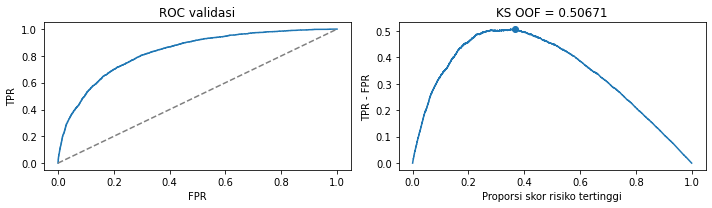

Ambang untuk memahami validasi: 0.116
Submission tetap probabilitas kontinu; ambang ini tidak diterapkan ke CSV.


In [18]:
validation_frame = validation
validation_probability = validation_frame["probability"].to_numpy()
y_valid = validation_frame.target.astype(int).to_numpy()
scores = metrics(y_valid, validation_probability)
assert (
    abs(
        scores["ks"]
        - ks_2samp(
            validation_probability[y_valid == 1], validation_probability[y_valid == 0]
        ).statistic
    )
    < 1e-12
)
display(pd.Series(scores, name="Baseline holdout 25%"))
fpr, tpr, thresholds = roc_curve(y_valid, validation_probability, drop_intermediate=False)
best = np.argmax(tpr - fpr)
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].plot(fpr, tpr)
axes[0].plot([0, 1], [0, 1], "--", color="gray")
axes[0].set(title="ROC validasi", xlabel="FPR", ylabel="TPR")
fraction = y_valid.mean() * tpr + (1 - y_valid.mean()) * fpr
axes[1].plot(fraction, tpr - fpr)
axes[1].scatter([fraction[best]], [tpr[best] - fpr[best]])
axes[1].set(
    title=f"KS OOF = {scores['ks']:.5f}",
    xlabel="Proporsi skor risiko tertinggi",
    ylabel="TPR - FPR",
)
plt.tight_layout()
plt.show()
print("Ambang untuk memahami validasi:", round(float(thresholds[best]), 4))
print("Submission tetap probabilitas kontinu; ambang ini tidak diterapkan ke CSV.")

## 12. Latih ulang baseline pada seluruh label dan prediksi test

Setelah mengevaluasi holdout, model final memakai seluruh 70.000 label. Cache yang dimuat adalah model final asli; bila tidak tersedia, Pipeline.fit dijalankan.

In [19]:
source_model = ROOT / "artifacts/submission_model.joblib"
local_model = OUT / "models/baseline_full.joblib"
cache = local_model if local_model.exists() else source_model
if cache.exists() and not FORCE_RETRAIN_MODELS:
    final_model = joblib.load(cache)
    actual = final_model.named_steps["model"].get_params()
    assert all(
        actual.get(k) == v for k, v in BASELINE_PARAMS.items()
    ), "Parameter cache berbeda; aktifkan FORCE_RETRAIN_MODELS."
else:
    encoder, _ = make_encoder(train_data[base_columns])
    final_model = Pipeline([("encode", encoder), ("model", XGBClassifier(**BASELINE_PARAMS))])
    final_model.fit(train_data[base_columns], train_data.target.astype(int))
    joblib.dump(final_model, local_model, compress=3)
test_probability = final_model.predict_proba(test_data[base_columns])[:, 1]

## Terakhir: hasilkan submission.csv

Kolom yang diminta adalah application_id dan default_probability. Merge satu-ke-satu memastikan urutan sample, lalu pemeriksaan membaca ulang CSV yang sudah ditulis. File historis/root tidak ditimpa. Bandingkan probabilitas dan SHA dengan checkpoint untuk memeriksa reproduksi. Selisih pembulatan kecil dapat muncul jika versi paket atau urutan penjumlahan berbeda.

In [20]:
# test_probability berada dalam urutan frame fitur, sehingga harus di-join ke sample.
predictions = pd.DataFrame(
    {
        "application_id": test_data.application_id.to_numpy(),
        "default_probability": np.asarray(test_probability),
    }
)
assert predictions.application_id.is_unique
assert set(predictions.application_id) == set(sample.application_id)
submission = sample[["application_id"]].merge(
    predictions, on="application_id", how="left", validate="one_to_one", sort=False
)
assert submission.shape == (len(sample), 2)
assert submission.application_id.equals(sample.application_id)
assert submission.columns.tolist() == ["application_id", "default_probability"]
assert np.isfinite(submission.default_probability).all()
assert submission.default_probability.between(0, 1).all()
destination = OUT / "submission.csv"
submission.to_csv(destination, index=False, float_format="%.12f")
reloaded = pd.read_csv(destination)
assert reloaded.application_id.equals(sample.application_id)
assert reloaded.columns.tolist() == sample.columns.tolist()
assert reloaded.default_probability.notna().all()
assert reloaded.default_probability.between(0, 1).all()
result = {
    "file": str(destination.relative_to(ROOT)),
    "rows": len(reloaded),
    "sha256": hashlib.sha256(destination.read_bytes()).hexdigest(),
    "historical_file": CANONICAL_FILE,
    "historical_public_score": PUBLIC_SCORE,
}
historical = ROOT / CANONICAL_FILE
if historical.exists():
    checkpoint = pd.read_csv(historical)
    assert checkpoint.application_id.equals(reloaded.application_id)
    result["maximum_probability_difference"] = float(
        np.max(
            np.abs(
                checkpoint.default_probability.to_numpy()
                - reloaded.default_probability.to_numpy()
            )
        )
    )
    result["matches_historical_predictions_1e9"] = (
        result["maximum_probability_difference"] < 1e-9
    )
    result["exact_sha256_match"] = (
        result["sha256"] == hashlib.sha256(historical.read_bytes()).hexdigest()
    )
(OUT / "verification.json").write_text(json.dumps(result, indent=2))
display(pd.Series(result, name="Pemeriksaan submission"))
display(reloaded.default_probability.describe().to_frame("probabilitas"))
print("CSV siap:", destination)

file                                  artifacts/notebook_runs/01_baseline/submission...
rows                                                                              30000
sha256                                60c12b5e13ba0bf14645fbd9d1247a4d6570892fd6ef83...
historical_file                       artifacts/optimization/submission_baseline_0_5...
historical_public_score                                                         0.52623
maximum_probability_difference                                                      0.0
matches_historical_predictions_1e9                                                 True
exact_sha256_match                                                                 True
Name: Pemeriksaan submission, dtype: object

,probabilitas
count,30000.000000
mean,0.135805
std,0.158491
min,0.002287
25%,0.029591
50%,0.071342
75%,0.179950
max,0.920056


CSV siap: /home/taqiyudinmiftah/Logika/artifacts/notebook_runs/01_baseline/submission.csv


## Pertanyaan untuk review kode

    1. Apakah semua riwayat diketahui sebelum keputusan aplikasi?
    2. Apakah ada ID, target, atau informasi setelah keputusan yang masuk ke fitur?
    3. Apakah encoder dan model dilatih hanya pada baris training setiap fold?
    4. Apakah pilihan jumlah pohon/bobot memakai validasi yang juga dilaporkan?
    5. Apakah probabilitas test dirata-ratakan dengan bobot yang benar?
    6. Apakah CSV mengikuti header dan urutan sample, tanpa index tambahan?

    Public score bukan KS validasi lokal. Saat Anda mengubah parameter, skor historis
    tidak otomatis menjadi skor model baru. Gunakan CSV dari sel terakhir untuk mencoba hasilnya.